# M6 Лабораторийн ажил — Барилгын эрчим хүчний Digital Twin прототип

Та Улаанбаатар хотын нэгэн хичээлийн байрны **Digital Twin**-ийн энгийн прототипийг
90 минутад бүтээнэ. Дасгалын заавар: `Digital Tools for Sustainability_M6_Lab_Instructions.docx`

Digital Twin-ийн 5 бүрэлдэхүүн хэсэг энэ файлд хэрхэн тусгагдсан бэ:
  Physical Entity       → хичээлийн байр (өгөгдлийн CSV-ээр төлөөлүүлсэн)
  Data Connection Layer → 1-р даалгавар: өгөгдөл ачаалах, цэвэрлэх
  Digital Replica       → 2-р даалгавар: 1R1C дулааны загвар + калибровк
  Analytical Engine     → 3, 4-р даалгавар: сценари, KPI, MCDA, Pareto
  Visualization         → 5-р даалгавар: dashboard

`# TODO` гэсэн хэсгүүдийг бөглөнө. Даалгавар бүрийн төгсгөлд `CHECKPOINT` шалгалт бий.
Ажиллуулах: VS Code-д "# %%" нүд тус бүрээр (Shift+Enter) эсвэл `python m6_lab_starter.py`

### 0. Тохиргоо ба таамаглалууд (assumptions) — өөрчлөхгүй

In [1]:
import time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    HERE = Path(__file__).resolve().parent
except NameError:            # Jupyter / Colab
    HERE = Path.cwd()
DATA = next(p / "data" / "building_sensor_data.csv" for p in (HERE, HERE.parent)
            if (p / "data" / "building_sensor_data.csv").exists())
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

COP = 2.0                 # дулааны насосны COP (таамаглал)
BASE_LOAD_KWH = 4.0       # халаалтаас бусад суурь цахилгаан ачаалал, кВт.ц/цаг
EF_KG_PER_KWH = 0.90      # цахилгааны сүлжээний ялгарлын коэффициент, кгCO2/кВт.ц (таамаглал)
TARIFF_MNT = 200          # цахилгааны тариф, ₮/кВт.ц (таамаглал)
P_MAX = 120.0             # халаалтын дээд чадал, кВт
COMFORT_MIN = 20.0        # хичээлийн цагт байх ёстой доод температур, °C
SEASON_FACTOR = 170 / 14  # улирлыг ≈170 "1-р сартай тэнцэх" хоног гэж тооцно (degree-day харьцаа, таамаглал)
RETROFIT_CAPEX_MNT = 90e6   # дулаалгын шинэчлэлийн хөрөнгө оруулалт (таамаглал)

### Даалгавар 0 — Өгөгдөлтэй танилцах

In [2]:
raw = pd.read_csv(DATA)
print("Байх ёстой мөр:", 14 * 24, "| Ирсэн мөр:", len(raw))
print(raw.isna().sum())
raw.describe().round(2)

Байх ёстой мөр: 336 | Ирсэн мөр: 334
timestamp     0
t_out_c       4
t_in_c       14
occupancy     0
heat_kw       0
elec_kwh      0
dtype: int64


,t_out_c,t_in_c,occupancy,heat_kw,elec_kwh
count,330.00,320.00,334.00,334.00,334.00
mean,-18.31,20.85,77.13,46.66,27.32
std,6.27,5.04,117.13,20.15,10.07
min,-32.65,-40.00,0.00,0.00,3.92
25%,-21.96,20.79,2.00,30.74,19.34
50%,-18.31,20.98,4.00,51.41,29.45
75%,-13.24,21.15,203.75,58.55,33.36
max,-6.90,85.00,318.00,120.00,64.41


### 1-р даалгавар — Data Connection Layer: өгөгдөл ачаалах ба цэвэрлэх (≈15 мин)

In [3]:
def load_and_clean(path):
    raw = pd.read_csv(path, parse_dates=["timestamp"]).set_index("timestamp")
    full_index = pd.date_range(raw.index.min(), raw.index.max(), freq="h")
    df = raw.reindex(full_index)          # алдагдсан мөрүүд NaN болж гарч ирнэ

    report = {"rows_expected": len(full_index),
              "rows_received": len(raw),
              "missing_rows": len(full_index) - len(raw)}



    bad_in = df["t_in_c"].notna() & ~df["t_in_c"].between(5, 35)
    bad_out = df["t_out_c"].notna() & ~df["t_out_c"].between(-50, 20)
    report["outliers_t_in"] = int(bad_in.sum())
    report["outliers_t_out"] = int(bad_out.sum())
    df.loc[bad_in, "t_in_c"] = np.nan
    df.loc[bad_out, "t_out_c"] = np.nan

    same = df["t_in_c"].diff().eq(0)
    run_id = (~same).cumsum()
    run_len = same.groupby(run_id).transform("sum")
    stuck = same & (run_len >= 3)                 # 3 тэнцүү алхам = 4 ижил утга
    report["stuck_t_in"] = int(stuck.sum())
    df.loc[stuck, "t_in_c"] = np.nan

    report["missing_t_in"] = int(df["t_in_c"].isna().sum())
    report["missing_t_out"] = int(df["t_out_c"].isna().sum())

    df["is_imputed"] = df["t_in_c"].isna() | df["t_out_c"].isna()
    for col in ["t_out_c", "t_in_c", "heat_kw", "elec_kwh"]:
        df[col] = df[col].interpolate(method="time", limit_direction="both")
    df["occupancy"] = df["occupancy"].fillna(0)

    df["p_int_kw"] = df["occupancy"] * 0.08 + 2.0          # хүн ~80 Вт + тоног төхөөрөмж 2 кВт
    df["occupied"] = (df.index.day_of_week < 5) & (df.index.hour >= 8) & (df.index.hour < 18)
    report["data_completeness_%"] = round(float(100 * (1 - df["is_imputed"].mean())), 1)
    return df, report


df, quality = load_and_clean(DATA)
print("Өгөгдлийн чанарын тайлан:", quality)

# CHECKPOINT 1
assert df[["t_in_c", "t_out_c", "heat_kw"]].notna().all().all(), "NaN үлдсэн байна → TODO 1.3"
assert df["t_in_c"].between(5, 35).all(), "Гажуудал үлдсэн байна → TODO 1.1"
print("✔ CHECKPOINT 1 давлаа")

Өгөгдлийн чанарын тайлан: {'rows_expected': 336, 'rows_received': 334, 'missing_rows': 2, 'outliers_t_in': 2, 'outliers_t_out': 0, 'stuck_t_in': 8, 'missing_t_in': 26, 'missing_t_out': 6, 'data_completeness_%': 91.1}
✔ CHECKPOINT 1 давлаа


### 2-р даалгавар — Digital Replica: 1R1C дулааны загвар ба калибровк (≈20 мин)

In [4]:
#
#   C · dT_in/dt = (T_out − T_in) / R + P_heat + P_int
#
#   R [K/kW]  — барилгын бүрхүүлийн дулааны эсэргүүцэл (их байх тусам сайн дулаалгатай)
#   C [kWh/K] — барилгын дулаан багтаамж (их байх тусам удаан хөрнө/халана)
#   Euler арга, dt = 1 цаг:  T[k+1] = T[k] + dt/C · ((T_out[k] − T[k])/R + P_heat[k] + P_int[k])

def simulate_temperature(t_out, p_heat, p_int, R, C, t0, dt=1.0):
    """Нээлттэй давталт (open-loop): хэмжсэн халаалтын чадлаар T_in-ийг таамаглана."""
    n = len(t_out)
    t_in = np.empty(n)
    t = t0
    for k in range(n):
        t_in[k] = t
        t = t + dt / C * ((t_out[k] - t) / R + p_heat[k] + p_int[k])
    return t_in


def metrics(measured, predicted):
    err = predicted - measured
    rmse = float(np.sqrt(np.mean(err ** 2)))
    cv_rmse = round(100 * rmse / float(np.mean(measured)), 2)
    nmbe = round(100 * float(np.sum(err)) / (len(measured) * float(np.mean(measured))), 2)
    return {"RMSE_C": round(rmse, 3), "CV_RMSE_%": cv_rmse, "NMBE_%": nmbe}


def calibrate(train, R_grid, C_grid):
    """Grid search: RMSE хамгийн бага байх (R, C) хосыг олно."""
    best = (np.inf, None, None)
    n_sims = 0
    for R in R_grid:
        for C in C_grid:
            pred = simulate_temperature(train["t_out_c"].values, train["heat_kw"].values,
                                        train["p_int_kw"].values, R, C, train["t_in_c"].iloc[0])
            n_sims += 1
            rmse = np.sqrt(np.mean((pred - train["t_in_c"].values) ** 2))
            if rmse < best[0]:
                best = (rmse, R, C)
    return best[1], best[2], n_sims


split = pd.Timestamp("2026-01-22 00:00")       # 10 хоног сургалт (train), 4 хоног баталгаажуулалт (test)
train, test = df[df.index < split], df[df.index >= split]

t0 = time.perf_counter()
R_hat, C_hat, n_sims = calibrate(train, np.arange(0.40, 1.21, 0.02), np.arange(20, 101, 2))
calib_seconds = time.perf_counter() - t0
print(f"Калибровк: R = {R_hat:.2f} K/kW, C = {C_hat:.0f} kWh/K ({n_sims} симуляц, {calib_seconds:.2f} сек)")
print(f"Цагийн тогтмол: τ = R·C = {R_hat * C_hat:.1f} цаг")

pred_train = simulate_temperature(train["t_out_c"].values, train["heat_kw"].values,
                                  train["p_int_kw"].values, R_hat, C_hat, train["t_in_c"].iloc[0])
pred_test = simulate_temperature(test["t_out_c"].values, test["heat_kw"].values,
                                 test["p_int_kw"].values, R_hat, C_hat, test["t_in_c"].iloc[0])
m_test = metrics(test["t_in_c"].values, pred_test)
print("Сургалтын алдаа:", metrics(train["t_in_c"].values, pred_train))
print("Баталгаажуулалтын алдаа:", m_test)

# CHECKPOINT 2 — ASHRAE Guideline 14 (цагийн өгөгдөл): CV(RMSE) ≤ 30 %, |NMBE| ≤ 10 %
assert m_test["CV_RMSE_%"] is not None and m_test["CV_RMSE_%"] <= 30, "CV(RMSE) шалгуур хангахгүй"
assert abs(m_test["NMBE_%"]) <= 10, "NMBE шалгуур хангахгүй"
print("✔ CHECKPOINT 2 давлаа — Twin баталгаажлаа")

Калибровк: R = 0.72 K/kW, C = 52 kWh/K (1681 симуляц, 0.50 сек)
Цагийн тогтмол: τ = R·C = 37.4 цаг
Сургалтын алдаа: {'RMSE_C': 0.461, 'CV_RMSE_%': 2.22, 'NMBE_%': 1.7}
Баталгаажуулалтын алдаа: {'RMSE_C': 0.342, 'CV_RMSE_%': 1.63, 'NMBE_%': -0.13}
✔ CHECKPOINT 2 давлаа — Twin баталгаажлаа


### 3-р даалгавар — Analytical Engine: "what-if" сценариуд (≈20 мин)

In [5]:
def setpoint_schedule(index, occupied_sp=21.0, setback_sp=None, preheat_start=8):
    """Цаг бүрийн тогтоосон температур (setpoint). setback_sp=None бол тогтмол."""
    sp = np.full(len(index), occupied_sp)
    if setback_sp is not None:
        weekday = index.day_of_week < 5
        on = weekday & (index.hour >= preheat_start) & (index.hour < 18)
        sp[~on] = setback_sp
    return sp


def run_scenario(df, R, C, setpoints, p_max=P_MAX):
    """Хаалттай давталт (closed-loop): идеал термостат + 1R1C загвар."""
    t_out, p_int = df["t_out_c"].values, df["p_int_kw"].values
    n = len(df)
    t_in, p_heat = np.empty(n), np.empty(n)
    t = setpoints[0]
    for k in range(n):
        # Термостат: дараагийн цагт яг setpoint-д хүрэхэд шаардлагатай чадал, [0, p_max]-д хязгаарлана
        need = C * (setpoints[k] - t) - (t_out[k] - t) / R - p_int[k]
        p = min(max(need, 0.0), p_max)
        t_in[k], p_heat[k] = t, p
        t = t + 1.0 / C * ((t_out[k] - t) / R + p + p_int[k])
    return t_in, p_heat


def kpis(df, t_in, p_heat, capex=0.0):
    elec = p_heat / COP + BASE_LOAD_KWH
    elec_kwh = elec.sum()
    return {"heat_MWh": round(p_heat.sum() / 1000, 2),
            "elec_MWh": round(elec_kwh / 1000, 2),
            "co2_t": round(elec_kwh * EF_KG_PER_KWH / 1000, 2),
            "cost_mn_MNT": round(elec_kwh * TARIFF_MNT / 1e6, 2),
            "discomfort_h": int(((t_in < COMFORT_MIN) & df["occupied"].values).sum()),
            "peak_kW": round(float(p_heat.max()), 1),
            "capex_mn_MNT": capex / 1e6}


SCENARIOS = {
    "S0 Суурь (21°C тогтмол)": dict(R_mult=1.0, sp=dict()),
    "S1 Шөнийн бууралт 16°C":  dict(R_mult=1.0, sp=dict(setback_sp=16.0)),
    "S2 Бууралт + 04:00 preheat": dict(R_mult=1.0, sp=dict(setback_sp=16.0, preheat_start=4)),
    "S3 Дулаалга (R×1.4)":      dict(R_mult=1.4, sp=dict(), capex=RETROFIT_CAPEX_MNT),
    "S4 S2 + S3":               dict(R_mult=1.4, sp=dict(setback_sp=16.0, preheat_start=4), capex=RETROFIT_CAPEX_MNT),
    "S5 Тогтмол 20°C":          dict(R_mult=1.0, sp=dict(occupied_sp=20.0)),
}

traces, rows = {}, []
for name, s in SCENARIOS.items():
    sp = setpoint_schedule(df.index, **s["sp"])
    t_in, p_heat = run_scenario(df, R_hat * s["R_mult"], C_hat, sp)
    traces[name] = t_in
    rows.append({"scenario": name, **kpis(df, t_in, p_heat, s.get("capex", 0.0))})

results = pd.DataFrame(rows).set_index("scenario")
base = results.iloc[0]
results["saving_%"] = (100 * (1 - results["elec_MWh"] / base["elec_MWh"])).round(1)
annual_saving_mnt = (base["cost_mn_MNT"] - results["cost_mn_MNT"]) * SEASON_FACTOR
results["payback_yr"] = np.where(results["capex_mn_MNT"] > 0,
                                 (results["capex_mn_MNT"] / annual_saving_mnt).round(1), 0.0)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print(results)

# CHECKPOINT 3
assert len(results) >= 6, "S2–S5 сценариудыг нэмээгүй байна → TODO 3.2"
assert results["discomfort_h"].notna().all(), "KPI дутуу → TODO 3.1"
print("✔ CHECKPOINT 3 давлаа")

                            heat_MWh  elec_MWh  co2_t  cost_mn_MNT  discomfort_h  peak_kW  capex_mn_MNT  saving_%  payback_yr
scenario                                                                                                                     
S0 Суурь (21°C тогтмол)        15.59      9.14   8.22         1.83             0     72.2           0.0       0.0         0.0
S1 Шөнийн бууралт 16°C         14.05      8.37   7.53         1.67            30    120.0           0.0       8.4         0.0
S2 Бууралт + 04:00 preheat     14.29      8.49   7.64         1.70             0    120.0           0.0       7.1         0.0
S3 Дулаалга (R×1.4)            10.35      6.52   5.87         1.30             0     50.9          90.0      28.7        14.0
S4 S2 + S3                      9.50      6.10   5.49         1.22             0    120.0          90.0      33.3        12.2
S5 Тогтмол 20°C                15.12      8.90   8.01         1.78             0     70.8           0.0       2.6     

### 4-р даалгавар — Олон шалгуурт шийдвэр (MCDA) ба Pareto (≈10 мин)

In [6]:
def pareto_front(points):
    """Бүх шалгуур бага байх нь сайн. Өөр нэг цэгээр "давамгайлагдаагүй" цэгүүдийг True болгоно."""
    pts = np.asarray(points, dtype=float)
    keep = np.ones(len(pts), dtype=bool)
    for i, p in enumerate(pts):
        others = np.delete(pts, i, axis=0)
        keep[i] = not np.any(np.all(others <= p, axis=1) & np.any(others < p, axis=1))
    return keep


def mcda(results, weights):
    """Жигнэсэн нийлбэр (weighted sum): min-max хэвшүүлэлт, 1 = хамгийн сайн."""
    crit = results[list(weights)]
    norm = (crit - crit.min()) / (crit.max() - crit.min()).replace(0, 1)
    return 1 - (norm * pd.Series(weights)).sum(axis=1)


results["pareto"] = pareto_front(results[["elec_MWh", "discomfort_h", "capex_mn_MNT"]].values)

# Санхүүгийн алба: төсөв хязгаартай тул хөрөнгө оруулалтад хамгийн их жин өгнө.
W_FINANCE = {"elec_MWh": 0.30, "discomfort_h": 0.20, "capex_mn_MNT": 0.50}
# Уур амьсгалын хөтөлбөр: CO2 нь цахилгаантай шууд пропорциональ тул цахилгаанд хамгийн их жин өгнө.
W_CLIMATE = {"elec_MWh": 0.60, "discomfort_h": 0.20, "capex_mn_MNT": 0.20}
results["score_finance"] = mcda(results, W_FINANCE).round(3)
results["score_climate"] = mcda(results, W_CLIMATE).round(3)
print(results[["elec_MWh", "discomfort_h", "capex_mn_MNT", "peak_kW", "pareto",
               "score_finance", "score_climate"]].sort_values("score_climate", ascending=False))

# Мэдрэмжийн шинжилгээ: нэг шалгуурын жинг +0.1, нөгөөгийнхийг -0.1 болгоно
print("Pareto front:", list(results.index[results["pareto"]]))
for label, W in (("Санхүү", W_FINANCE), ("Уур амьсгал", W_CLIMATE)):
    leader = mcda(results, W).idxmax()
    leaders = set()
    for up in W:
        for down in W:
            if up != down:
                w = dict(W)
                w[up] = round(w[up] + 0.1, 2)
                w[down] = round(w[down] - 0.1, 2)
                leaders.add(mcda(results, w).idxmax())
    print(f"{label}: тэргүүлэгч = {leader}; жин өөрчлөхөд = {sorted(leaders)}")

                            elec_MWh  discomfort_h  capex_mn_MNT  peak_kW  pareto  score_finance  score_climate
scenario                                                                                                       
S4 S2 + S3                      6.10             0          90.0    120.0    True          0.500          0.800
S3 Дулаалга (R×1.4)             6.52             0          90.0     50.9   False          0.459          0.717
S2 Бууралт + 04:00 preheat      8.49             0           0.0    120.0    True          0.764          0.528
S5 Тогтмол 20°C                 8.90             0           0.0     70.8   False          0.724          0.447
S0 Суурь (21°C тогтмол)         9.14             0           0.0     72.2   False          0.700          0.400
S1 Шөнийн бууралт 16°C          8.37            30           0.0    120.0    True          0.576          0.352
Pareto front: ['S1 Шөнийн бууралт 16°C', 'S2 Бууралт + 04:00 preheat', 'S4 S2 + S3']
Санхүү: тэргүүлэгч 

### 5-р даалгавар — Visualization Interface: dashboard (≈10 мин)

Хадгалсан: output/dashboard.png


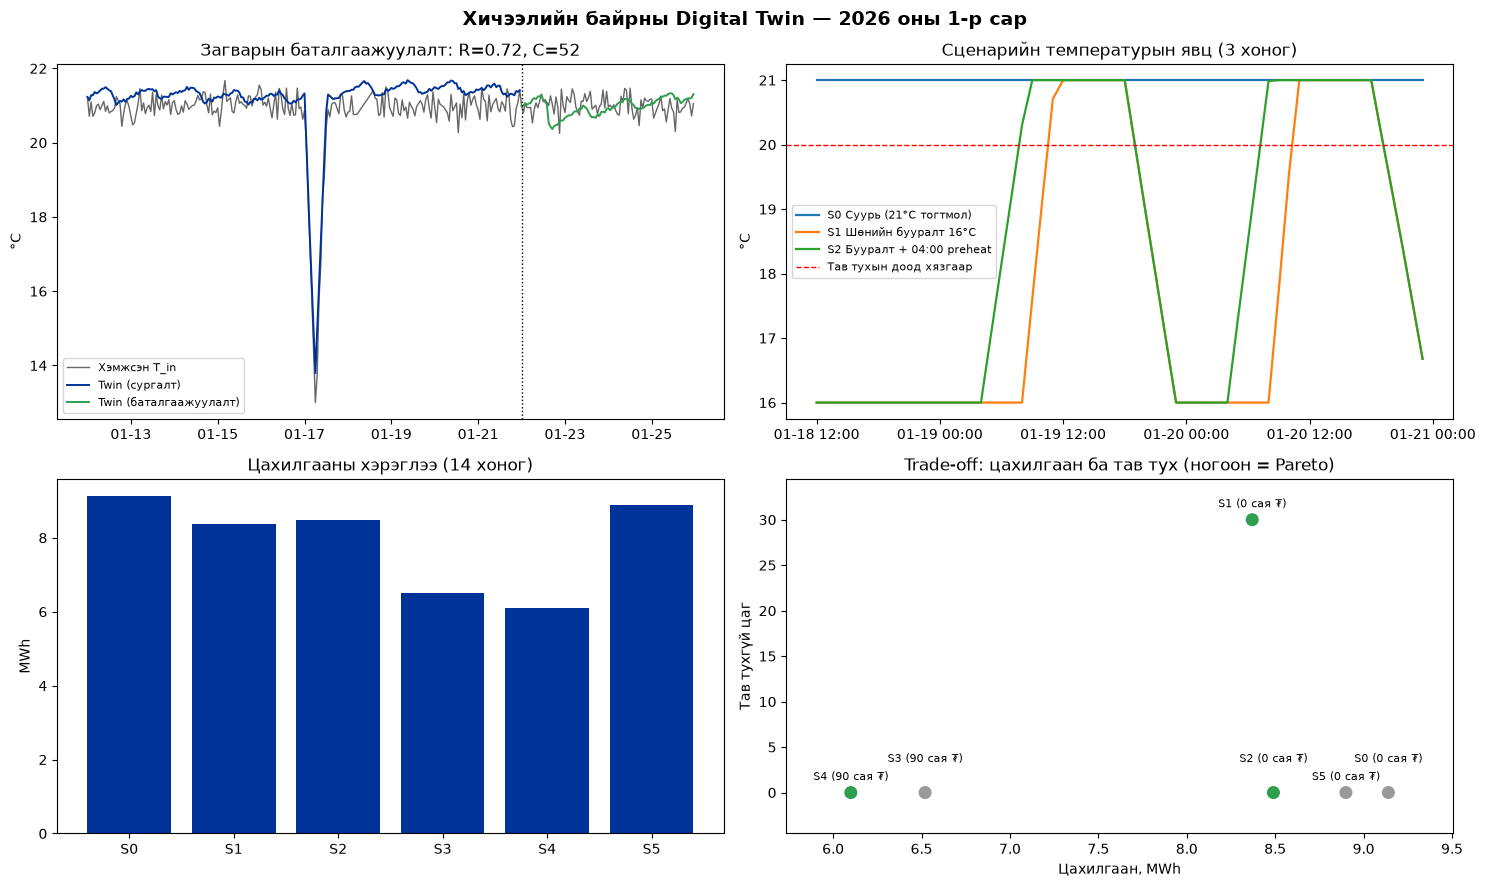

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle("Хичээлийн байрны Digital Twin — 2026 оны 1-р сар", fontsize=14, fontweight="bold")

a = ax[0, 0]
a.plot(df.index, df["t_in_c"], color="0.4", lw=1, label="Хэмжсэн T_in")
a.plot(train.index, pred_train, color="#003399", lw=1.4, label="Twin (сургалт)")
a.plot(test.index, pred_test, color="#2E9E4F", lw=1.4, label="Twin (баталгаажуулалт)")
a.axvline(split, color="k", ls=":", lw=1)
a.set_title(f"Загварын баталгаажуулалт: R={R_hat:.2f}, C={C_hat:.0f}")
a.set_ylabel("°C"); a.legend(fontsize=8)
a.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

a = ax[0, 1]
win = (df.index >= "2026-01-18 12:00") & (df.index < "2026-01-21 00:00")
for name in list(traces)[:3]:
    a.plot(df.index[win], traces[name][win], lw=1.6, label=name)
a.axhline(COMFORT_MIN, color="r", ls="--", lw=1, label="Тав тухын доод хязгаар")
a.set_title("Сценарийн температурын явц (3 хоног)"); a.set_ylabel("°C"); a.legend(fontsize=8)
a.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
a.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))

a = ax[1, 0]
labels = [n.split(" ")[0] for n in results.index]
a.bar(labels, results["elec_MWh"], color="#003399")
a.set_title("Цахилгааны хэрэглээ (14 хоног)"); a.set_ylabel("MWh")

a = ax[1, 1]
colors = np.where(results["pareto"], "#2E9E4F", "0.6")
a.scatter(results["elec_MWh"], results["discomfort_h"], c=colors, s=70)
for i, (name, r) in enumerate(results.sort_values("elec_MWh").iterrows()):
    a.annotate(f'{name.split(" ")[0]} ({r["capex_mn_MNT"]:.0f} сая ₮)', (r["elec_MWh"], r["discomfort_h"]),
               xytext=(0, 9 if i % 2 == 0 else 22), textcoords="offset points", ha="center", fontsize=8)
a.margins(x=0.12, y=0.15)
a.set_title("Trade-off: цахилгаан ба тав тух (ногоон = Pareto)")
a.set_xlabel("Цахилгаан, MWh"); a.set_ylabel("Тав тухгүй цаг")

fig.tight_layout()
fig.savefig(OUT / "dashboard.png", dpi=150)
results.to_csv(OUT / "scenario_results.csv", encoding="utf-8-sig")
print("Хадгалсан:", OUT / "dashboard.png")

### 6. Тооцооллын ул мөр (computational footprint) — тусгалд ашиглана

In [8]:
print(f"Калибровк {n_sims} симуляц, {calib_seconds:.2f} сек. "
      f"Grid-ийн нягтыг 2 дахин нэмбэл ≈{4 * calib_seconds:.1f} сек болно.")

Калибровк 1681 симуляц, 0.50 сек. Grid-ийн нягтыг 2 дахин нэмбэл ≈2.0 сек болно.
